# 02. Посимвольная TF-IDF векторизация и Grid Search

* Векторизатор — **только посимвольные n-граммы** (`analyzer="char"`): они улавливают морфологию,
  пунктуацию, служебные слова и орфографию эпохи — то есть стиль, а не тему.
* **Пайплайн 1:** лемматизация (`pymorphy3`) → char TF-IDF.
* **Пайплайн 2:** сырой очищенный текст → char TF-IDF.
* Сетка: `ngram_range ∈ {(2,4), (3,5), (3,6)}`, `max_features ∈ {10k, 25k, 50k}`, `sublinear_tf ∈ {True, False}`.
* Оценка — на официальной **validation**-выборке (фрагменты ~1000 символов).

In [1]:
import functools
import re
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymorphy3
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import LinearSVC

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
PROCESSED, MODELS, FIG, REPORTS = ROOT / "data/processed", ROOT / "models", ROOT / "reports/figures", ROOT / "reports"
MODELS.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")

In [2]:
train = pd.read_parquet(PROCESSED / "chunks_train.parquet")
val = pd.read_parquet(PROCESSED / "chunks_validation.parquet")
print("train chunks:", len(train), "| validation chunks:", len(val))

label_encoder = LabelEncoder().fit(train["author"])
print("Классов (авторов):", len(label_encoder.classes_))

train chunks: 110285 | validation chunks: 9735
Классов (авторов): 64


### Подвыборка для Grid Search
36 конфигураций на ~110 тыс. фрагментов — слишком дорого, поэтому поиск ведётся на
стратифицированной подвыборке: до 300 фрагментов на автора из train (редкие авторы берутся целиком)
и 5 000 случайных фрагментов validation.

In [3]:
gs_train = train.sample(frac=1.0, random_state=SEED).groupby("author").head(300)
gs_val = val.sample(5000, random_state=SEED)
y_gs_tr = label_encoder.transform(gs_train["author"])
y_gs_va = label_encoder.transform(gs_val["author"])
print("grid-train:", len(gs_train), "| grid-val:", len(gs_val))

grid-train: 16809 | grid-val: 5000


### Пайплайн 1: лемматизация `pymorphy3`

In [4]:
morph = pymorphy3.MorphAnalyzer()
TOKEN_RE = re.compile(r"\w+|[^\w\s]")


@functools.lru_cache(maxsize=500_000)
def lemma(word: str) -> str:
    return morph.parse(word)[0].normal_form


def lemmatize(text: str) -> str:
    return " ".join(lemma(t) if t[0].isalnum() else t for t in TOKEN_RE.findall(text.lower()))


print(gs_train["text"].iloc[0][:300])
print("→", lemmatize(gs_train["text"].iloc[0])[:300])

вот что. Неужли ты в самом деле отправляешься в деревню? Звёздов. Неужлн!.. Сейчас лошадей приведут. Звёздова. А я здесь остаюсь? Звёздов. Здесь. Звёздова. Как же я останусь? Звёздов. Так же, как останешься. Звёздова. С чем? Звёздов. Как с чем? Звёздова. Да у меня ничего нет. Звёздов. Как ничего? вс
→ вот что . неужть ты в сам дело отправляться в деревня ? звёзд . неужлна ! . . сейчас лошадь привести . звёздов . а я здесь оставаться ? звёзд . здесь . звёздов . как же я остаться ? звёзд . так же , как остаться . звёздов . с чем ? звёзд . как с чем ? звёздов . да у я ничего нет . звёзд . как ничего


In [5]:
t0 = time.perf_counter()
gs_train_lem = [lemmatize(t) for t in gs_train["text"]]
gs_val_lem = [lemmatize(t) for t in gs_val["text"]]
lem_total = time.perf_counter() - t0
print(f"Лемматизация {len(gs_train_lem) + len(gs_val_lem)} фрагментов: {lem_total:.1f} c")

# Оверхед на «холодный» запрос (без кэша лемм) — то, что увидит сервис на инференсе
lemma.cache_clear()
probe = val["text"].iloc[:200].tolist()
t0 = time.perf_counter()
for t in probe:
    lemmatize(t)
cold_ms = (time.perf_counter() - t0) / len(probe) * 1000
print(f"Холодная лемматизация одного фрагмента ~1000 символов: {cold_ms:.1f} мс")

Лемматизация 21809 фрагментов: 11.1 c


Холодная лемматизация одного фрагмента ~1000 символов: 1.9 мс


### Grid Search

Для ускорения для каждого `ngram_range` строится **одна** матрица счётчиков `CountVectorizer`,
а `max_features` применяется отбором top-k признаков по суммарной частоте в корпусе — ровно так
же, как это делает `TfidfVectorizer(max_features=k)` внутри (`_limit_features`). Затем
`TfidfTransformer(sublinear_tf=…)` и линейный классификатор `LinearSVC` как быстрый «пробник»
качества признаков. Конфигурации обучаются параллельно.

In [6]:
NGRAMS = [(2, 4), (3, 5), (3, 6)]
MAX_FEATURES = [10_000, 25_000, 50_000]
SUBLINEAR = [True, False]


def evaluate_config(Xtr_c, Xva_c, order, k, sublinear):
    cols = np.sort(order[:k])
    tfidf = TfidfTransformer(sublinear_tf=sublinear)
    Xtr = tfidf.fit_transform(Xtr_c[:, cols])
    Xva = tfidf.transform(Xva_c[:, cols])
    clf = LinearSVC(C=0.5, random_state=SEED).fit(Xtr, y_gs_tr)
    pred = clf.predict(Xva)
    return {
        "max_features": k,
        "sublinear_tf": sublinear,
        "accuracy": accuracy_score(y_gs_va, pred),
        "f1_macro": f1_score(y_gs_va, pred, average="macro"),
    }


results = []
inputs = {
    "1_lemmatized": (gs_train_lem, gs_val_lem),
    "2_raw": (gs_train["text"].tolist(), gs_val["text"].tolist()),
}
for pipe_name, (tr_texts, va_texts) in inputs.items():
    for ngram in NGRAMS:
        t0 = time.perf_counter()
        cv = CountVectorizer(analyzer="char", ngram_range=ngram, lowercase=True, dtype=np.float32)
        Xtr_c = cv.fit_transform(tr_texts)
        Xva_c = cv.transform(va_texts)
        order = np.argsort(-np.asarray(Xtr_c.sum(axis=0)).ravel(), kind="stable")
        res = Parallel(n_jobs=6)(
            delayed(evaluate_config)(Xtr_c, Xva_c, order, k, s) for k in MAX_FEATURES for s in SUBLINEAR
        )
        for r in res:
            r.update(pipeline=pipe_name, ngram_range=str(ngram))
        results.extend(res)
        best = max(res, key=lambda r: r["f1_macro"])
        print(f"{pipe_name:<13} ngram={ngram}  vocab={Xtr_c.shape[1]:>9,}  best F1={best['f1_macro']:.4f}  ({time.perf_counter() - t0:.0f} c)")

grid = pd.DataFrame(results)[["pipeline", "ngram_range", "max_features", "sublinear_tf", "accuracy", "f1_macro"]]
grid.to_csv(REPORTS / "tfidf_grid_search.csv", index=False)
grid.sort_values("f1_macro", ascending=False).head(10)

1_lemmatized  ngram=(2, 4)  vocab=  147,699  best F1=0.6989  (117 c)


1_lemmatized  ngram=(3, 5)  vocab=  536,462  best F1=0.6872  (120 c)


1_lemmatized  ngram=(3, 6)  vocab=1,536,497  best F1=0.6782  (120 c)


2_raw         ngram=(2, 4)  vocab=  249,039  best F1=0.6934  (94 c)


2_raw         ngram=(3, 5)  vocab=  948,273  best F1=0.6763  (103 c)


2_raw         ngram=(3, 6)  vocab=2,827,158  best F1=0.6654  (116 c)


,pipeline,ngram_range,max_features,sublinear_tf,accuracy,f1_macro
4,1_lemmatized,"(2, 4)",50000,True,0.8464,0.698875
22,2_raw,"(2, 4)",50000,True,0.8404,0.693352
10,1_lemmatized,"(3, 5)",50000,True,0.8356,0.687238
2,1_lemmatized,"(2, 4)",25000,True,0.8310,0.685035
20,2_raw,"(2, 4)",25000,True,0.8232,0.679577
16,1_lemmatized,"(3, 6)",50000,True,0.8256,0.678244
28,2_raw,"(3, 5)",50000,True,0.8290,0.676349
11,1_lemmatized,"(3, 5)",50000,False,0.8238,0.672589
23,2_raw,"(2, 4)",50000,False,0.8214,0.671106
5,1_lemmatized,"(2, 4)",50000,False,0.8216,0.670950


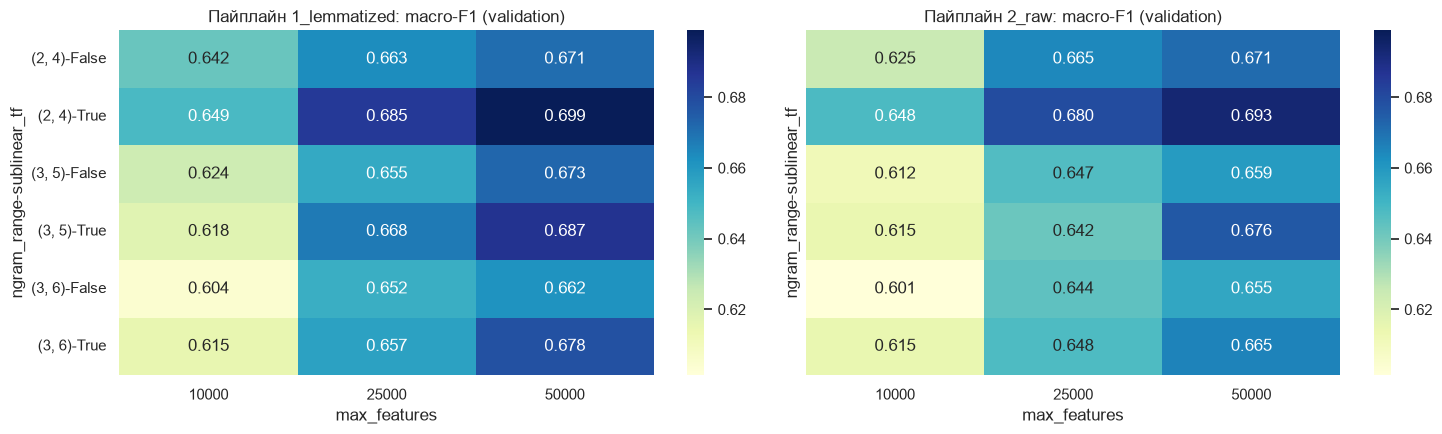

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (name, g) in zip(axes, grid.groupby("pipeline")):
    pv = g.pivot_table(index=["ngram_range", "sublinear_tf"], columns="max_features", values="f1_macro")
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, vmin=grid.f1_macro.min(), vmax=grid.f1_macro.max())
    ax.set_title(f"Пайплайн {name}: macro-F1 (validation)")
plt.tight_layout()
plt.savefig(FIG / "tfidf_grid_heatmap.png", dpi=120)
plt.show()

In [8]:
summary = grid.loc[grid.groupby("pipeline")["f1_macro"].idxmax()].reset_index(drop=True)
summary["lemmatization_ms_per_request"] = [cold_ms if p.startswith("1") else 0.0 for p in summary["pipeline"]]
summary

,pipeline,ngram_range,max_features,sublinear_tf,accuracy,f1_macro,lemmatization_ms_per_request
0,1_lemmatized,"(2, 4)",50000,True,0.8464,0.698875,1.880053
1,2_raw,"(2, 4)",50000,True,0.8404,0.693352,0.000000


### Выбор для продакшена

Согласно ТЗ, в продакшен идёт **пайплайн без лемматизации**: он не требует морфологического
разбора на каждом запросе (см. оверхед выше), а посимвольные n-граммы по сырому тексту сохраняют
окончания, частицы и пунктуацию — главные стилевые маркеры, которые лемматизация стирает.
Выбирается лучшая по macro-F1 конфигурация пайплайна 2.

In [9]:
best_raw = grid[grid.pipeline == "2_raw"].sort_values(["f1_macro", "accuracy"], ascending=False).iloc[0]
BEST = {
    "ngram_range": tuple(int(x) for x in best_raw["ngram_range"].strip("()").split(",")),
    "max_features": int(best_raw["max_features"]),
    "sublinear_tf": bool(best_raw["sublinear_tf"]),
}
print("Лучшая конфигурация (без лемматизации):", BEST, f"F1={best_raw['f1_macro']:.4f}")

Лучшая конфигурация (без лемматизации): {'ngram_range': (2, 4), 'max_features': 50000, 'sublinear_tf': True} F1=0.6934


### Обучение финального векторизатора
Словарь и IDF оцениваются на стратифицированной выборке фрагментов train (до 800 на автора, ≈40 тыс.):
это даёт устойчивую статистику n-грамм без многогигабайтного промежуточного словаря на всём корпусе.

In [10]:
fit_sample = train.sample(frac=1.0, random_state=SEED).groupby("author").head(800)
t0 = time.perf_counter()
vectorizer = TfidfVectorizer(analyzer="char", lowercase=True, dtype=np.float32, **BEST)
vectorizer.fit(fit_sample["text"])
vectorizer.stop_words_ = None  # не тащим в pickle миллионы отброшенных n-грамм
print(f"fit на {len(fit_sample)} фрагментах: {time.perf_counter() - t0:.0f} c, признаков: {len(vectorizer.vocabulary_)}")

joblib.dump(vectorizer, MODELS / "tfidf_vectorizer.pkl")
joblib.dump(label_encoder, MODELS / "label_encoder.pkl")
for f in ("tfidf_vectorizer.pkl", "label_encoder.pkl"):
    print(f"{f:<22} {(MODELS / f).stat().st_size / 2**20:.2f} MB")

fit на 36372 фрагментах: 31 c, признаков: 50000


tfidf_vectorizer.pkl   1.56 MB
label_encoder.pkl      0.00 MB


In [11]:
probe_text = val["text"].iloc[0]
t0 = time.perf_counter()
for _ in range(50):
    vectorizer.transform([probe_text])
print(f"Векторизация одного запроса: {(time.perf_counter() - t0) / 50 * 1000:.2f} мс")
print("Примеры признаков:", list(vectorizer.vocabulary_)[:15])

Векторизация одного запроса: 1.02 мс
Примеры признаков: ['во', 'от', 'т ', ' ч', 'чт', 'то', 'о.', '. ', ' н', 'не', 'еу', 'уж', 'жл', 'ли', 'и ']
